# Specimen Registration & 3D Volume Preparation Pipeline

This notebook has two independent parts.

- **Part A — Method validation (A.1–A.4):** a controlled experiment for the soutenance. It starts from a known-good Atlas volume, applies known rigid perturbations to real embryo serial sections, runs the same VALIS registration configuration used in production, and compares the registered result with the original ground truth.
- **Part B — Production pipeline (B.1 onward):** processes a real specimen supplied by a researcher. It accepts either an already assembled Atlas/volume source or a raw serial-section archive/folder, registers raw sections with VALIS when requested, builds one calibrated grayscale 3D volume, writes a manifest and QC reports, and optionally pushes the result to Hugging Face.

Part A never feeds data into Part B. If you remove the Part A cells, Part B still runs normally.

**Current scope:** this notebook produces the registered grayscale volume and metadata. Segmentation, surface reconstruction and GLB export remain downstream modules.


In [ ]:
# ============================================================
# PARAMETERS
# ------------------------------------------------------------
# This cell is tagged `parameters`: the pipeline runner / web form
# injects values for every variable below (papermill), and everything
# after this cell derives its paths and settings from them.
# Running the notebook by hand uses these defaults, which reproduce
# the original CS17 run.
# ============================================================

# Local scratch root. Kaggle: "/kaggle/working"; Colab: "/content".
WORK_DIR = "/kaggle/working"

# ---------------- specimen ----------------
SPECIMEN_ID = "CS17-6521"
SPECIMEN_DESC = "Carnegie Stage 17, specimen 6521"
# "atlas_am_volume"    -> a pre-assembled, already-aligned Atlas grey volume (.tif + .am header)
# "raw_section_archive" -> a researcher's own serial sections (registrations runs first)
SPECIMEN_FORMAT = "atlas_am_volume"

# --- atlas input (SPECIMEN_FORMAT == "atlas_am_volume") ---
ATLAS_GREY_TIF_URL = "http://3datlas.3dembryo.nl/3DAtlas_CS17-6521-grey-v2016-01.tif"
ATLAS_AM_URL = "http://3datlas.3dembryo.nl/3DAtlas_CS17-6521-grey-v2016-01.am"

# --- raw serial-section input (SPECIMEN_FORMAT == "raw_section_archive") ---
RAW_INPUT_MODE = "url"       # "url" | "local_archive" | "local_folder"
RAW_ARCHIVE_URL = None       # zip/tar of the sections, or a huggingface.co/... file URL
RAW_LOCAL_PATH = None        # path to an archive/folder already present locally

# Required for raw serial sections (physical scale of the input images).
RESEARCHER_SUPPLIED_METADATA = {
    "xy_pixel_size_um": None,
    "z_cutting_interval_um": None,
    "units": "um",
}

# ---------------- registration behaviour ----------------
REGISTRATION_MODE = "always"  # "always" | "never" | "auto"
USE_NON_RIGID_OUTPUT = False
VALIS_MAX_PROCESSED_IMAGE_DIM_PX = 1024
ALLOW_SECTION_NUMBER_GAPS = False

# ---------------- output ----------------
PUSH_TO_HF = True
# ONE shared dataset for the whole project: volumes/<specimen>/ (this notebook)
# and viewers/<specimen>/ (3D notebook). It must be PUBLIC so a website can fetch
# the viewer files; Atlas data is public anyway. For unpublished/private specimens
# point HF_REPO_ID at a different, private dataset instead.
HF_REPO_ID = "senku111/embryo-3d"
HF_PRIVATE = False

# ============================================================ # end parameters # ====

## Production output

For each specimen, everything lands in ONE shared Hugging Face dataset (`HF_REPO_ID`), one sub-folder per specimen:

```text
volumes/<SPECIMEN_ID>/
    <SPECIMEN_ID>_grey.tif
    <SPECIMEN_ID>_manifest.json      (shape, voxel size, sha256, registration + QC info)
    reports/contact_sheet.png
    reports/registration_error_df.csv        (raw sections only)
    reports/registration_summary.json        (raw sections only)

slices/<SPECIMEN_ID>/
    slice_0000.webp ... slice_NNNN.webp      (one image per z-plane, for instant hover preview)
    slices_manifest.json
```

Running the pipeline for another specimen simply adds another `volumes/<OTHER_ID>/` and `slices/<OTHER_ID>/` folder. The 3D reconstruction notebook writes its web bundle next to it under `viewers/<SPECIMEN_ID>/`.

The grayscale TIFF is the main input for downstream segmentation/3D notebooks. The manifest is the source of truth for voxel spacing, section order, registration status and provenance.


# Shared setup

This section contains reusable utilities. It deliberately does **not** reinstall NumPy/SciPy in the Kaggle kernel. VALIS runs inside its own isolated virtual environment.


In [1]:
import os, sys, subprocess, zipfile, tarfile, time, json, re, textwrap, shutil
from pathlib import Path

# Required by tifffile for LZW-compressed TIFF files
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "imagecodecs"],
    check=True
)

import numpy as np
import tifffile
import matplotlib.pyplot as plt

try:
    import cv2
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"], check=True)
    import cv2

try:
    from PIL import Image
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow"], check=True)
    from PIL import Image

try:
    import requests
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "requests"], check=True)
    import requests

from tqdm.auto import tqdm

def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

def clean_env():
    env = os.environ.copy()
    for k in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "MPLBACKEND"):
        env.pop(k, None)
    env["PYTHONNOUSERSITE"] = "1"
    env["MPLBACKEND"] = "Agg"
    return env

def download(url, dest, max_retries=3, connect_timeout=15, read_timeout=120):
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        log(f"skip download: {dest.name} already exists ({dest.stat().st_size/1e6:.1f} MB)")
        return dest

    headers = {"User-Agent": "Mozilla/5.0 (research pipeline)"}
    urls = [url]
    if url.startswith("http://"):
        urls.append("https://" + url[len("http://"):])

    last_error = None
    for u in urls:
        for attempt in range(1, max_retries + 1):
            try:
                with requests.get(u, headers=headers, stream=True,
                                  timeout=(connect_timeout, read_timeout)) as r:
                    r.raise_for_status()
                    total = int(r.headers.get("content-length", 0))
                    with open(dest, "wb") as f:
                        with tqdm(total=total, unit="B", unit_scale=True, desc=dest.name) as bar:
                            for chunk in r.iter_content(chunk_size=1 << 20):
                                if chunk:
                                    f.write(chunk)
                                    bar.update(len(chunk))
                return dest
            except Exception as e:
                last_error = e
                if dest.exists():
                    dest.unlink()
                time.sleep(2 * attempt)
    raise RuntimeError(f"[DATA PROBLEM] could not download {url}: {last_error}")

def ncc(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    a -= a.mean()
    b -= b.mean()
    denom = np.sqrt(np.sum(a*a) * np.sum(b*b))
    return 0.0 if denom == 0 else float(np.sum(a*b) / denom)

def stack_ncc(volume):
    if volume.shape[0] < 2:
        return np.array([], dtype=float)
    return np.array([ncc(volume[i], volume[i+1]) for i in range(volume.shape[0]-1)])

def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a, dtype=np.float64) -
                                np.asarray(b, dtype=np.float64))))

def read_image_gray(path):
    path = Path(path)
    if path.name.lower().endswith(".ome.tiff") or path.suffix.lower() in {".tif", ".tiff"}:
        arr = tifffile.imread(path)
    else:
        arr = np.array(Image.open(path).convert("L"))
    arr = np.asarray(arr)
    while arr.ndim > 2:
        arr = arr[0]
    if arr.ndim != 2:
        raise RuntimeError(f"[DATA PROBLEM] expected 2D grayscale section: {path}, got {arr.shape}")
    return arr

def numeric_from_name(path):
    nums = re.findall(r"\d+", Path(path).stem)
    return int(nums[-1]) if nums else None

VENV_DIR = Path("{WORK_DIR}/valis_venv")

def venv_has_valis(venv_python, env):
    if not venv_python.exists():
        return False
    check = (
        "import valis, skimage; "
        "from packaging.version import parse; "
        "assert parse(skimage.__version__) < parse('0.25')"
    )
    r = subprocess.run([str(venv_python), "-c", check],
                       capture_output=True, text=True, env=env)
    return r.returncode == 0

def ensure_valis_venv():
    venv_python = VENV_DIR / "bin" / "python"
    env = clean_env()
    if venv_has_valis(venv_python, env):
        log("VALIS venv already present and verified.")
        return venv_python, env

    log("Building isolated VALIS venv...")
    subprocess.run(["apt-get", "update", "-q"], check=False)
    subprocess.run(["apt-get", "install", "-y", "-q", "libvips42", "libvips-dev"], check=True)
    subprocess.run([sys.executable, "-m", "venv", "--without-pip", str(VENV_DIR)],
                   check=True, env=env)

    get_pip = VENV_DIR / "get-pip.py"
    download("https://bootstrap.pypa.io/get-pip.py", get_pip)
    subprocess.run([str(venv_python), str(get_pip), "-q"], check=True, env=env)
    subprocess.run([str(venv_python), "-m", "pip", "install", "-q",
                    "valis-wsi", "scikit-image==0.24.0"],
                   check=True, env=env)

    if not venv_has_valis(venv_python, env):
        raise RuntimeError("[ENVIRONMENT PROBLEM] VALIS venv verification failed.")
    return venv_python, env

def run_valis_registration(section_dir, results_dir, venv_python, env,
                            force_non_rigid=False, max_processed_image_dim_px=1024):
    section_dir = Path(section_dir)
    results_dir = Path(results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)
    script = results_dir / "_run_valis.py"

    script_text = r'''
import os
os.environ["MPLBACKEND"] = "Agg"
import json, traceback
from pathlib import Path
from valis import registration

stage_dir = Path(__STAGE_DIR__)
results_dir = Path(__RESULTS_DIR__)
force_non_rigid = __FORCE_NON_RIGID__
max_processed_image_dim_px = __MAX_DIM__

try:
    image_exts = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
    files = sorted([p for p in stage_dir.iterdir()
                    if p.is_file() and p.suffix.lower() in image_exts])
    if len(files) < 3:
        raise RuntimeError("Need at least 3 serial sections for production registration.")

    reference_img = files[len(files)//2].name

    registrar = registration.Valis(
        str(stage_dir),
        str(results_dir),
        imgs_ordered=True,
        reference_img_f=reference_img,
        align_to_reference=True,
        crop="reference",
        do_rigid=True,
        max_processed_image_dim_px=max_processed_image_dim_px,
    )

    rigid_registrar, non_rigid_registrar, error_df = registrar.register()
    if error_df is None:
        raise RuntimeError("VALIS returned error_df=None; rigid registration failed.")

    error_df.to_csv(results_dir / "error_df.csv", index=False)
    summary = error_df.describe().to_dict()

    rigid_med = summary.get("rigid_D", {}).get("50%")
    nonrigid_med = summary.get("non_rigid_D", {}).get("50%")

    use_non_rigid = bool(force_non_rigid)
    decision_note = "forced non-rigid output" if use_non_rigid else "production default: rigid output only"

    warped_dir = results_dir / "warped"
    registrar.warp_and_save_slides(
        str(warped_dir),
        non_rigid=use_non_rigid,
        crop="reference",
        compression="lzw",
    )

    status = {
        "ok": True,
        "reference_img": reference_img,
        "imgs_ordered": True,
        "align_to_reference": True,
        "crop": "reference",
        "max_processed_image_dim_px": max_processed_image_dim_px,
        "non_rigid_used": use_non_rigid,
        "decision_note": decision_note,
        "summary": summary,
        "rigid_D_median": rigid_med,
        "non_rigid_D_median": nonrigid_med,
    }
except Exception:
    status = {"ok": False, "traceback": traceback.format_exc()}
finally:
    registration.kill_jvm()

(results_dir / "valis_status.json").write_text(
    json.dumps(status, default=str, indent=2)
)
'''

    script_text = (script_text
                   .replace("__STAGE_DIR__", repr(str(section_dir)))
                   .replace("__RESULTS_DIR__", repr(str(results_dir)))
                   .replace("__FORCE_NON_RIGID__", repr(bool(force_non_rigid)))
                   .replace("__MAX_DIM__", repr(int(max_processed_image_dim_px))))
    script.write_text(script_text)

    r = subprocess.run([str(venv_python), str(script)],
                       env=env, capture_output=True, text=True)

    status_file = results_dir / "valis_status.json"
    if not status_file.exists():
        print(r.stdout[-5000:])
        print(r.stderr[-5000:])
        raise RuntimeError("[VALIS ERROR] No valis_status.json was produced.")

    status = json.loads(status_file.read_text())
    if not status["ok"]:
        print(r.stdout[-5000:])
        print(r.stderr[-5000:])
        raise RuntimeError("[VALIS ERROR]\n" + status["traceback"])

    return results_dir / "warped", status

print("Shared setup ready.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 59.3 MB/s eta 0:00:00
Shared setup ready.


# PART A — Registration Method Validation

This is the **soutenance/test section**.

It uses five consecutive real embryo slices from a known-good Atlas volume, deliberately applies known rotations/translations, and asks VALIS to recover them. It is a method calibration, not proof that every future histology dataset will register perfectly.


## A.1 — Load the known-good Atlas ground truth


In [3]:
VALIDATION_DIR = Path("{WORK_DIR}/registration_validation")
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

GROUND_TRUTH_VOLUME_URL = (
    "http://3datlas.3dembryo.nl/"
    "3DAtlas_CS15-3512-grey-v2016-01.tif"
)

ground_truth_path = VALIDATION_DIR / "ground_truth_grey.tif"
download(GROUND_TRUTH_VOLUME_URL, ground_truth_path)
ground_truth_volume = tifffile.imread(ground_truth_path)

print("Ground-truth volume shape:", ground_truth_volume.shape)


ground_truth_grey.tif:   0%|          | 0.00/1.04G [00:00<?, ?B/s]

Ground-truth volume shape: (651, 2266, 1383)


## A.2 — Create real serial sections with known rigid perturbations


In [4]:
import shutil

TEST_DIR = VALIDATION_DIR / "real_serial_calibration"
SYN_DIR = TEST_DIR / "synthetic_sections"

if TEST_DIR.exists():
    shutil.rmtree(TEST_DIR)
SYN_DIR.mkdir(parents=True, exist_ok=True)

serial_indices = np.array([323, 324, 325, 326, 327])
original_serial_stack = ground_truth_volume[serial_indices].astype(np.float32)

true_rotations_deg = np.array([-4.0, -2.0, 0.0, 2.5, 4.0], dtype=np.float32)
true_shifts_px = np.array([
    [-12.0,  10.0],
    [ -6.0,  -7.0],
    [  0.0,   0.0],
    [  8.0,   5.0],
    [ 14.0, -10.0],
], dtype=np.float32)

perturbed_stack = []
for i, img in enumerate(original_serial_stack):
    H, W = img.shape
    M_rot = cv2.getRotationMatrix2D((W/2.0, H/2.0),
                                    float(true_rotations_deg[i]), 1.0)
    rotated = cv2.warpAffine(
        img, M_rot, (W, H), flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=float(np.median(img))
    )

    row_shift, col_shift = true_shifts_px[i]
    M_shift = np.array([[1.0, 0.0, col_shift],
                        [0.0, 1.0, row_shift]], dtype=np.float32)

    shifted = cv2.warpAffine(
        rotated, M_shift, (W, H), flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=float(np.median(img))
    )

    perturbed_stack.append(shifted)
    tifffile.imwrite(
        SYN_DIR / f"section_{i:03d}.tif",
        np.clip(shifted, 0, 65535).astype(np.uint16)
    )

perturbed_stack = np.stack(perturbed_stack)

print("Serial slices:", serial_indices.tolist())
print("Known rotations:", true_rotations_deg.tolist())
print("Known shifts:", true_shifts_px.tolist())
print("Perturbed shape:", perturbed_stack.shape)


Serial slices: [323, 324, 325, 326, 327]
Known rotations: [-4.0, -2.0, 0.0, 2.5, 4.0]
Known shifts: [[-12.0, 10.0], [-6.0, -7.0], [0.0, 0.0], [8.0, 5.0], [14.0, -10.0]]
Perturbed shape: (5, 2266, 1383)


## A.3 — Run the same rigid VALIS configuration used for production


In [5]:
venv_python, venv_env = ensure_valis_venv()

warped_dir, valis_status = run_valis_registration(
    SYN_DIR,
    TEST_DIR / "valis_output",
    venv_python,
    venv_env,
    force_non_rigid=False,
)

print(json.dumps({
    "reference_img": valis_status["reference_img"],
    "imgs_ordered": valis_status["imgs_ordered"],
    "align_to_reference": valis_status["align_to_reference"],
    "crop": valis_status["crop"],
    "non_rigid_used": valis_status["non_rigid_used"],
}, indent=2))


[00:32:49] Building isolated VALIS venv...
Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [114 kB]
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:6 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Get:9 https://cli.github.com/packages stable/main amd64 Packages [359 B]
Hit:10 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:11 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:12 http://archive.ubuntu.com/ubuntu jammy-updates/multiverse amd64 Packages [93.2 kB]
Get:13 http://security.ubuntu.com/ubuntu jammy-secur

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)



Building dependency tree...
Reading state information...
The following additional packages will be installed:
  apparmor firefox gettext gettext-base gir1.2-gsf-1 gir1.2-poppler-0.18
  gir1.2-vips-8.0 libatk1.0-0 libatk1.0-data libcgif-dev libcgif0
  libdatrie-dev libfftw3-bin libfftw3-dev libfftw3-long3 libfftw3-quad3
  libfftw3-single3 libfribidi-dev libfuse3-3 libgail-common libgail18
  libgraphite2-3 libgraphite2-dev libgsf-1-114 libgsf-1-common libgsf-1-dev
  libgsl27 libgslcblas0 libgtk2.0-0 libgtk2.0-bin libgtk2.0-common
  libharfbuzz-dev libharfbuzz-gobject0 libharfbuzz-icu0 libimagequant-dev
  libimagequant0 libmatio-dev libmatio11 libopenslide-dev libopenslide0
  liborc-0.4-0 liborc-0.4-dev liborc-0.4-dev-bin libpam-systemd
  libpango1.0-dev libpoppler-dev libpoppler-glib-dev libpoppler-glib8
  libpoppler-private-dev libpoppler118 libsystemd0 libthai-dev libudev1
  libvips-doc libvips-tools libxcomposite1 nip2 pango1.0-tools snapd
  squashfs-tools systemd systemd-hwe-hwdb sy

get-pip.py:   0%|          | 0.00/2.23M [00:00<?, ?B/s]

Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


{
  "reference_img": "section_002.tif",
  "imgs_ordered": true,
  "align_to_reference": true,
  "crop": "reference",
  "non_rigid_used": false
}


## A.4 — Quantitative validation and visual evidence


VALIS REAL-SERIAL CALIBRATION RESULT
Slice 323: known rot=-4.00°, shift=(-12.0,+10.0) | MAE 20.101->21.312 | NCC 0.5423->0.5211
Slice 324: known rot=-2.00°, shift=(-6.0,-7.0) | MAE 17.220->14.404 | NCC 0.6407->0.6857
Slice 325: known rot=+0.00°, shift=(+0.0,+0.0) | MAE 0.000->0.000 | NCC 1.0000->1.0000
Slice 326: known rot=+2.50°, shift=(+8.0,+5.0) | MAE 17.692->14.749 | NCC 0.6083->0.6639
Slice 327: known rot=+4.00°, shift=(+14.0,-10.0) | MAE 19.230->20.259 | NCC 0.5326->0.5193

Median MAE: 17.692 -> 14.749
Median NCC: 0.6083 -> 0.6639
MAE improved: 40.0%
NCC improved: 40.0%


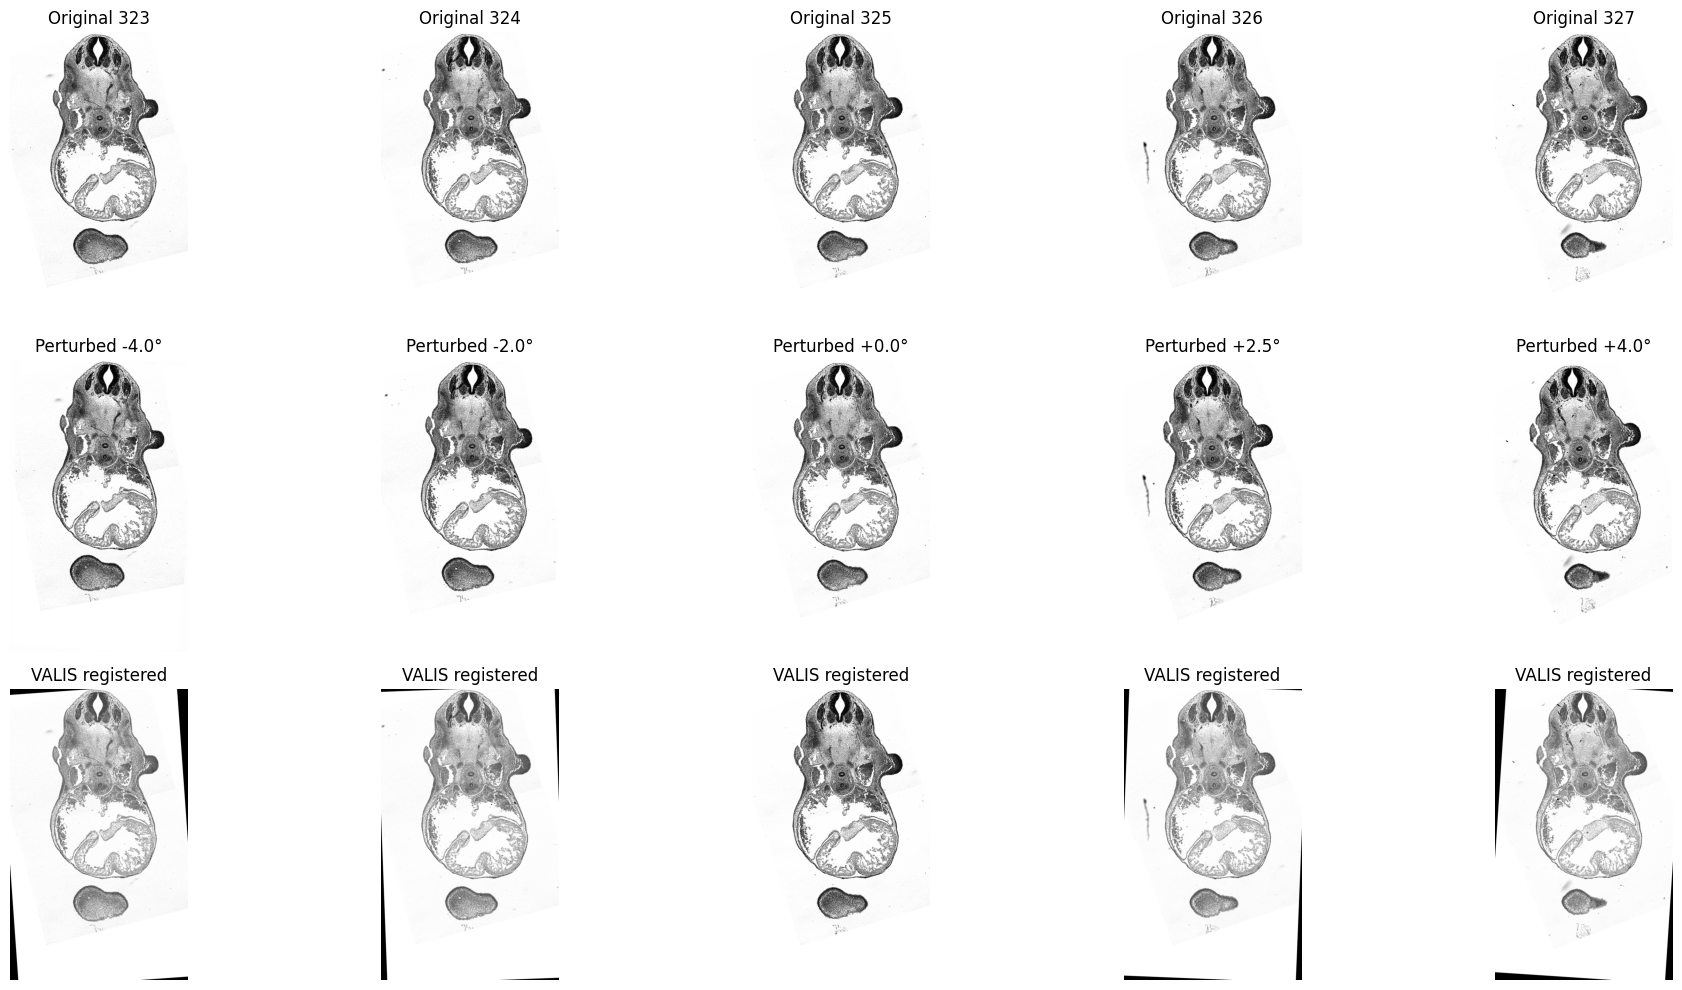

In [6]:
registered_files = sorted(Path(warped_dir).glob("*.ome.tiff"))
registered_stack = np.stack([
    tifffile.imread(f).astype(np.float32)
    for f in registered_files
])

mae_before, mae_after = [], []
ncc_before, ncc_after = [], []

for i in range(len(serial_indices)):
    H = min(original_serial_stack[i].shape[0], registered_stack[i].shape[0])
    W = min(original_serial_stack[i].shape[1], registered_stack[i].shape[1])

    a = original_serial_stack[i][:H, :W]
    b = perturbed_stack[i][:H, :W]
    c = registered_stack[i][:H, :W]

    mae_before.append(mae(a, b))
    mae_after.append(mae(a, c))
    ncc_before.append(ncc(a, b))
    ncc_after.append(ncc(a, c))

mae_before = np.array(mae_before)
mae_after = np.array(mae_after)
ncc_before = np.array(ncc_before)
ncc_after = np.array(ncc_after)

print("=" * 72)
print("VALIS REAL-SERIAL CALIBRATION RESULT")
print("=" * 72)
for i, idx in enumerate(serial_indices):
    print(
        f"Slice {idx}: known rot={true_rotations_deg[i]:+.2f}°, "
        f"shift=({true_shifts_px[i,0]:+.1f},{true_shifts_px[i,1]:+.1f}) | "
        f"MAE {mae_before[i]:.3f}->{mae_after[i]:.3f} | "
        f"NCC {ncc_before[i]:.4f}->{ncc_after[i]:.4f}"
    )

print(f"\nMedian MAE: {np.median(mae_before):.3f} -> {np.median(mae_after):.3f}")
print(f"Median NCC: {np.median(ncc_before):.4f} -> {np.median(ncc_after):.4f}")
print(f"MAE improved: {100*np.mean(mae_after < mae_before):.1f}%")
print(f"NCC improved: {100*np.mean(ncc_after > ncc_before):.1f}%")

def norm_display(x):
    lo, hi = np.percentile(x, [1, 99])
    return np.clip((x-lo)/(hi-lo+1e-8), 0, 1)

fig, axes = plt.subplots(3, len(serial_indices), figsize=(20, 10))
for i in range(len(serial_indices)):
    axes[0,i].imshow(norm_display(original_serial_stack[i]), cmap="gray")
    axes[0,i].set_title(f"Original {serial_indices[i]}")
    axes[1,i].imshow(norm_display(perturbed_stack[i]), cmap="gray")
    axes[1,i].set_title(f"Perturbed {true_rotations_deg[i]:+.1f}°")
    axes[2,i].imshow(norm_display(registered_stack[i]), cmap="gray")
    axes[2,i].set_title("VALIS registered")
    for r in range(3):
        axes[r,i].axis("off")
plt.tight_layout()
plt.show()


# PART B — Production pipeline

**This is the part another researcher would use.**

Supported inputs:

1. `atlas_am_volume` — an already assembled grayscale volume plus `.am` header. It is treated as already ordered/aligned; calibration is read from the header.
2. `raw_section_archive` — individual serial sections in a folder/archive. The notebook orders them numerically, requires physical calibration from the researcher, and normally runs VALIS rigid registration.

The output is a single calibrated grayscale volume plus a manifest and QC artifacts.


## B.1 — Specimen configuration


In [2]:
# ---------------- USER CONFIGURATION ----------------


# Raw serial-section input:

# Required for raw serial sections.



# ONE shared dataset for the whole project: volumes/<specimen>/ (this notebook) and viewers/<specimen>/ (3D notebook).
# It must be PUBLIC so a website can fetch the viewer files; Atlas data is public anyway.
# For unpublished/private specimens, point HF_REPO_ID at a different, private dataset instead.

BASE_DIR = Path(f"{WORK_DIR}/specimen_{SPECIMEN_ID.replace('-', '_')}")
RAW_DIR = BASE_DIR / "raw"
ORDERED_DIR = BASE_DIR / "ordered"
RESULTS_DIR = BASE_DIR / "registration_results"
VOLUME_DIR = BASE_DIR / "volume"
REPORT_DIR = BASE_DIR / "reports"

for d in [RAW_DIR, ORDERED_DIR, RESULTS_DIR, VOLUME_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

GREY_TIF = VOLUME_DIR / f"{SPECIMEN_ID}_grey.tif"
MANIFEST = VOLUME_DIR / f"{SPECIMEN_ID}_manifest.json"

print(f"Specimen: {SPECIMEN_ID}")
print(f"Format:   {SPECIMEN_FORMAT}")


Specimen: CS17-6521
Format:   atlas_am_volume


## B.2 — Acquire the input


In [3]:
if SPECIMEN_FORMAT == "atlas_am_volume":
    download(ATLAS_GREY_TIF_URL, RAW_DIR / "source_grey.tif")
    # Only the text header of the .am is parsed (first 2 MB) -> read just that, not the whole ~0.9 GB file.
    def download_am_header(url, dest, nbytes=2_000_000):
        dest = Path(dest)
        if dest.exists() and dest.stat().st_size > 1000:
            log(f"skip: {dest.name} header already present"); return dest
        last = None
        for u in [url] + ([ "https://" + url[len("http://"):] ] if url.startswith("http://") else []):
            try:
                with requests.get(u, headers={"Range": f"bytes=0-{nbytes-1}",
                                              "User-Agent": "Mozilla/5.0 (research pipeline)"},
                                  stream=True, timeout=(15, 120)) as r:
                    r.raise_for_status()
                    data = b""
                    for chunk in r.iter_content(1 << 16):
                        data += chunk
                        if len(data) >= nbytes: break
                dest.write_bytes(data[:nbytes]); return dest
            except Exception as e:
                last = e
        raise RuntimeError(f"[DATA PROBLEM] could not read .am header from {url}: {last}")
    download_am_header(ATLAS_AM_URL, RAW_DIR / "source_grey.am")
    volume = np.asarray(tifffile.imread(RAW_DIR / "source_grey.tif"))

    if volume.ndim != 3:
        raise RuntimeError(f"[DATA PROBLEM] expected 3D Atlas volume, got {volume.shape}")
    print("Loaded Atlas volume:", volume.shape, volume.dtype)

elif SPECIMEN_FORMAT == "raw_section_archive":
    if RAW_INPUT_MODE == "url":
        if not RAW_ARCHIVE_URL:
            raise RuntimeError("[INPUT REQUIRED] Set RAW_ARCHIVE_URL.")
        archive_path = RAW_DIR / Path(RAW_ARCHIVE_URL).name
        download(RAW_ARCHIVE_URL, archive_path)

    elif RAW_INPUT_MODE in {"local_archive", "local_folder"}:
        if not RAW_LOCAL_PATH:
            raise RuntimeError("[INPUT REQUIRED] Set RAW_LOCAL_PATH.")
        source_path = Path(RAW_LOCAL_PATH)
        if not source_path.exists():
            raise RuntimeError(f"[DATA PROBLEM] Input does not exist: {source_path}")
        archive_path = source_path

    else:
        raise RuntimeError(f"Unknown RAW_INPUT_MODE: {RAW_INPUT_MODE}")

    if RAW_INPUT_MODE == "local_folder":
        extract_dir = Path(RAW_LOCAL_PATH)
    else:
        extract_dir = RAW_DIR / "extracted"
        extract_dir.mkdir(parents=True, exist_ok=True)

        file_type = subprocess.run(
            ["file", "-b", str(archive_path)],
            capture_output=True, text=True
        ).stdout.lower()

        if "rar" in file_type or archive_path.suffix.lower() == ".rar":
            subprocess.run(["apt-get", "update", "-q"], check=False)
            subprocess.run(["apt-get", "install", "-y", "-q", "unrar"], check=False)
            subprocess.run(
                ["unrar", "x", "-y", str(archive_path), str(extract_dir) + "/"],
                check=True
            )
        elif archive_path.suffix.lower() in {".tar", ".gz", ".tgz", ".bz2", ".xz"}:
            with tarfile.open(archive_path) as tf:
                tf.extractall(extract_dir)
        else:
            try:
                with zipfile.ZipFile(archive_path) as zf:
                    zf.extractall(extract_dir)
            except zipfile.BadZipFile:
                raise RuntimeError(
                    "[DATA PROBLEM] Unsupported archive. Provide ZIP/RAR/TAR or a local folder."
                )

    volume = None
    print("Raw section source:", extract_dir)

else:
    raise RuntimeError(f"Unknown SPECIMEN_FORMAT: {SPECIMEN_FORMAT}")


source_grey.tif:   0%|          | 0.00/1.31G [00:00<?, ?B/s]

Loaded Atlas volume: (1059, 1821, 1126) uint8


## B.3 — Discover and order raw serial sections


In [4]:
if SPECIMEN_FORMAT == "raw_section_archive":
    IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

    all_files = [
        p for p in extract_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    if len(all_files) < 3:
        raise RuntimeError(f"[DATA PROBLEM] Found only {len(all_files)} image files.")

    from collections import Counter
    counts = Counter(p.parent for p in all_files)
    source_dir, source_count = counts.most_common(1)[0]

    print(f"Candidate section directory: {source_dir}")
    print(f"Images found there: {source_count}")

    candidate_files = [
        p for p in source_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    parsed = [(p, numeric_from_name(p)) for p in candidate_files]

    if any(n is None for _, n in parsed):
        raise RuntimeError(
            "[DATA PROBLEM] Some section filenames do not contain a numeric index."
        )

    parsed.sort(key=lambda x: x[1])
    section_numbers = [n for _, n in parsed]

    if len(section_numbers) != len(set(section_numbers)):
        raise RuntimeError("[DATA PROBLEM] Duplicate numeric section IDs detected.")

    gaps = [b-a for a,b in zip(section_numbers, section_numbers[1:])]
    bad_gaps = [g for g in gaps if g != 1]

    print(f"Sections: {len(parsed)}")
    print(f"Section-number range: {section_numbers[0]} -> {section_numbers[-1]}")
    print(f"Unique gaps: {sorted(set(gaps))}")

    if bad_gaps and not ALLOW_SECTION_NUMBER_GAPS:
        raise RuntimeError(
            "[STOP] Missing/non-consecutive section numbers detected. "
            "Confirm how missing sections should be represented physically before proceeding."
        )

    for i, (src, original_number) in enumerate(parsed):
        dst = ORDERED_DIR / f"{i:05d}_{original_number:06d}{src.suffix.lower()}"
        if not dst.exists():
            shutil.copy2(src, dst)

    ordered_files = sorted(ORDERED_DIR.iterdir())
    print(f"Ordered section directory: {ORDERED_DIR}")
else:
    section_numbers = None
    ordered_files = []
    print("Atlas mode: ordering is already encoded in the volume.")


Atlas mode: ordering is already encoded in the volume.


## B.4 — Decide whether registration is required


In [5]:
if SPECIMEN_FORMAT == "atlas_am_volume":
    RUN_VALIS = False
    decision_note = "Atlas volume is already assembled/aligned; no registration required."
else:
    if REGISTRATION_MODE == "always":
        RUN_VALIS = True
        decision_note = "Raw serial sections: VALIS forced on by production policy."
    elif REGISTRATION_MODE == "never":
        RUN_VALIS = False
        decision_note = "Registration explicitly disabled by user."
    elif REGISTRATION_MODE == "auto":
        sample_files = ordered_files[::max(1, len(ordered_files)//30)]
        preview = []
        for f in sample_files:
            img = read_image_gray(f)
            preview.append(cv2.resize(img, (512,512), interpolation=cv2.INTER_AREA))
        preview_ncc = stack_ncc(np.stack(preview))
        med = float(np.median(preview_ncc))
        outlier_count = int(np.sum(
            preview_ncc < med - 3*float(np.std(preview_ncc))
        ))
        RUN_VALIS = bool(
            med < 0.55 or outlier_count > max(1, int(0.05*len(preview)))
        )
        decision_note = (
            f"Auto decision from preview NCC: median={med:.3f}, "
            f"outliers={outlier_count} -> RUN_VALIS={RUN_VALIS}"
        )
    else:
        raise RuntimeError(f"Unknown REGISTRATION_MODE: {REGISTRATION_MODE}")

print("RUN_VALIS:", RUN_VALIS)
print(decision_note)


RUN_VALIS: False
Atlas volume is already assembled/aligned; no registration required.


## B.5 — Run VALIS registration for raw serial sections


In [6]:
if RUN_VALIS:
    venv_python, venv_env = ensure_valis_venv()

    warped_dir, valis_status = run_valis_registration(
        ORDERED_DIR,
        RESULTS_DIR,
        venv_python,
        venv_env,
        force_non_rigid=USE_NON_RIGID_OUTPUT,
        max_processed_image_dim_px=VALIS_MAX_PROCESSED_IMAGE_DIM_PX,
    )

    shutil.copy2(
        RESULTS_DIR / "error_df.csv",
        REPORT_DIR / "registration_error_df.csv"
    )
    (REPORT_DIR / "registration_summary.json").write_text(
        json.dumps(valis_status, indent=2, default=str)
    )

    print("VALIS output:", warped_dir)
    print("Reference:", valis_status["reference_img"])
    print("Rigid D median:", valis_status["rigid_D_median"])
else:
    warped_dir = None
    valis_status = None
    print("VALIS skipped.")


VALIS skipped.


## B.6 — Build the final grayscale volume


In [7]:
if SPECIMEN_FORMAT == "atlas_am_volume":
    final_volume = np.asarray(volume)
else:
    source_dir = warped_dir if RUN_VALIS else ORDERED_DIR
    files = sorted([
        p for p in Path(source_dir).iterdir()
        if p.is_file() and (
            p.name.lower().endswith(".ome.tiff") or
            p.suffix.lower() in {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
        )
    ])

    if len(files) != len(ordered_files):
        raise RuntimeError(
            f"[DATA PROBLEM] Expected {len(ordered_files)} output sections, found {len(files)}."
        )

    imgs = [read_image_gray(f) for f in files]
    shapes = {im.shape for im in imgs}

    if len(shapes) > 1:
        max_h = max(im.shape[0] for im in imgs)
        max_w = max(im.shape[1] for im in imgs)
        print(f"Non-uniform output shapes detected; center-padding to {(max_h,max_w)}.")
        padded = []
        for im in imgs:
            canvas = np.zeros((max_h,max_w), dtype=im.dtype)
            y0 = (max_h-im.shape[0])//2
            x0 = (max_w-im.shape[1])//2
            canvas[y0:y0+im.shape[0], x0:x0+im.shape[1]] = im
            padded.append(canvas)
        imgs = padded

    final_volume = np.stack(imgs, axis=0)

print("Final volume:", final_volume.shape, final_volume.dtype)

if final_volume.dtype.kind == "f":
    final_volume = np.clip(final_volume, 0, 65535).astype(np.uint16)
elif final_volume.dtype.itemsize > 2:
    final_volume = np.clip(final_volume, 0, 65535).astype(np.uint16)

tifffile.imwrite(GREY_TIF, final_volume, compression="zlib")
print("Written:", GREY_TIF)


Final volume: (1059, 1821, 1126) uint8
Written: /kaggle/working/specimen_CS17_6521/volume/CS17-6521_grey.tif


## B.7 — Resolve physical calibration


In [8]:
EXPECTED_GREATEST_LENGTH_MM_RANGE = (7.0, 9.0)

def parse_am_header(am_path, max_header_bytes=2_000_000):
    with open(am_path, "rb") as f:
        text = f.read(max_header_bytes).decode("latin-1", errors="ignore")

    dims_match = re.search(r"define\s+Lattice\s+(\d+)\s+(\d+)\s+(\d+)", text)
    bbox_match = re.search(
        r"BoundingBox\s+([-\d.eE]+)\s+([-\d.eE]+)\s+([-\d.eE]+)\s+"
        r"([-\d.eE]+)\s+([-\d.eE]+)\s+([-\d.eE]+)",
        text
    )
    units_match = re.search(
        r'Units\s*\{\s*Coordinates\s+"([^"]+)"', text
    )

    if not dims_match or not bbox_match:
        raise RuntimeError("[DATA PROBLEM] Could not parse Lattice/BoundingBox from .am header.")

    nx, ny, nz = map(int, dims_match.groups())
    xmin, xmax, ymin, ymax, zmin, zmax = map(float, bbox_match.groups())

    return {
        "dims": (nx, ny, nz),
        "bbox_extent": (xmax-xmin, ymax-ymin, zmax-zmin),
        "declared_units": units_match.group(1) if units_match else None,
    }

def resolve_atlas_calibration(am_info):
    nx, ny, nz = am_info["dims"]
    ex, ey, ez = am_info["bbox_extent"]

    unit = (am_info["declared_units"] or "").lower()
    factors = {
        "um": 1.0, "micron": 1.0, "micrometer": 1.0,
        "mm": 1000.0, "millimeter": 1000.0,
    }

    if unit:
        if unit not in factors:
            raise RuntimeError(f"[DATA PROBLEM] Unknown .am units: {unit}")
        factor = factors[unit]
        provenance = f".am explicitly declares units='{unit}'"
    else:
        lo, hi = EXPECTED_GREATEST_LENGTH_MM_RANGE
        longest = max(ex, ey, ez)
        candidates = []
        if lo*0.5 <= longest <= hi*1.5:
            candidates.append(("already_mm", 1000.0))
        if lo*0.5 <= longest/1000.0 <= hi*1.5:
            candidates.append(("already_um", 1.0))

        if len(candidates) != 1:
            raise RuntimeError(
                f"[DATA PROBLEM] .am unit is ambiguous. Candidates={candidates}."
            )

        factor = candidates[0][1]
        provenance = f"unit inferred from Atlas plausibility check: {candidates[0][0]}"

    xy = ((ex/max(nx-1,1)) + (ey/max(ny-1,1))) / 2 * factor
    z = ez/max(nz-1,1) * factor

    return {
        "xy_pixel_size_um": float(xy),
        "z_spacing_um": float(z),
        "units": "um",
        "provenance": provenance,
    }

if SPECIMEN_FORMAT == "atlas_am_volume":
    am_info = parse_am_header(RAW_DIR / "source_grey.am")
    calibration = resolve_atlas_calibration(am_info)
else:
    missing = [
        k for k in ("xy_pixel_size_um", "z_cutting_interval_um")
        if RESEARCHER_SUPPLIED_METADATA.get(k) is None
    ]
    if missing:
        raise RuntimeError(
            "[INPUT REQUIRED] Missing researcher calibration: " + ", ".join(missing)
        )

    calibration = {
        "xy_pixel_size_um": float(RESEARCHER_SUPPLIED_METADATA["xy_pixel_size_um"]),
        "z_spacing_um": float(RESEARCHER_SUPPLIED_METADATA["z_cutting_interval_um"]),
        "units": RESEARCHER_SUPPLIED_METADATA.get("units", "um"),
        "provenance": "researcher_supplied",
    }

print(json.dumps(calibration, indent=2))


{
  "xy_pixel_size_um": 4.479279981159951,
  "z_spacing_um": 10.0,
  "units": "um",
  "provenance": "unit inferred from Atlas plausibility check: already_um"
}


## B.8 — Quantitative QC, preview and manifest


Post-processing NCC: {'median': 0.8784046854975744, 'mean': 0.8584597608876994, 'min': 0.0, 'max': 1.0}


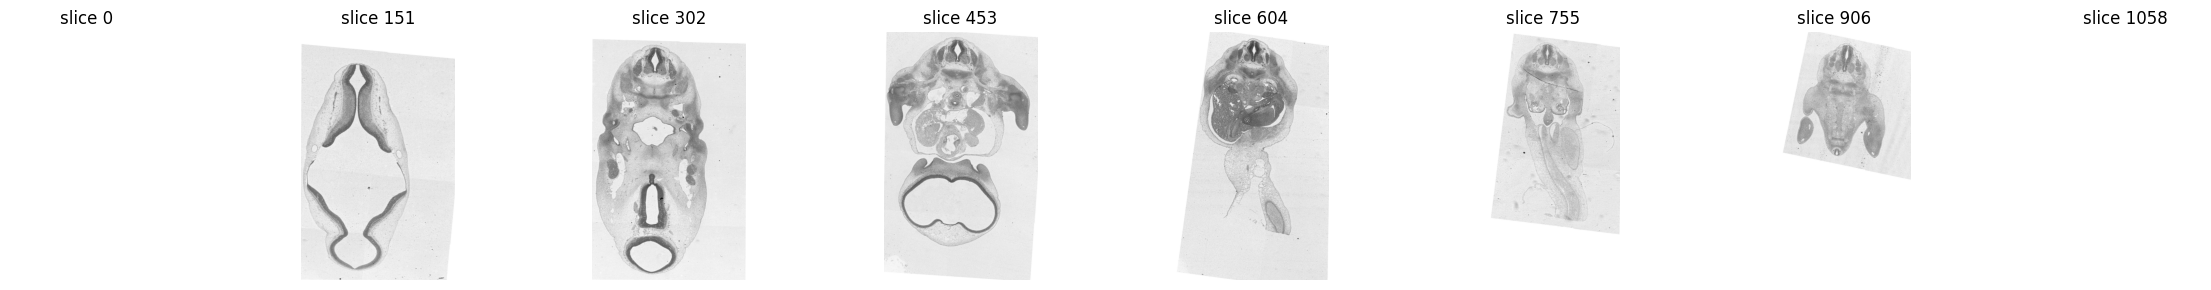

Contact sheet: /kaggle/working/specimen_CS17_6521/reports/contact_sheet.png
Constant/empty candidate slices: [0, 1058]
Mostly-zero slices: []
Completely white slices: [0, 1058]

FINAL VOLUME SANITY CHECK
Shape : (1059, 1821, 1126)
Dtype : uint8
Min   : 0
Max   : 255
Mean  : 227.3522662906558
Std   : 33.03448614044878

MANIFEST SAVED
/kaggle/working/specimen_CS17_6521/volume/CS17-6521_manifest.json

{
  "specimen_id": "CS17-6521",
  "description": "Carnegie Stage 17, specimen 6521",
  "specimen_format": "atlas_am_volume",
  "volume_file": "volumes/CS17-6521/CS17-6521_grey.tif",
  "volume_sha256": "07294ca70be02290fdaa6337f62fdcdfe8244ea649c671278dddd9eed9fda165",
  "volume_bytes": 1108377465,
  "shape_zyx": [
    1059,
    1821,
    1126
  ],
  "dtype": "uint8",
  "xy_pixel_size_um": 4.479279981159951,
  "z_spacing_um": 10.0,
  "units": "um",
  "calibration_provenance": "unit inferred from Atlas plausibility check: already_um",
  "registration": {
    "run_valis": false,
    "use_non_ri

In [9]:
# ============================================================
# FINAL QC + CONTACT SHEET + MANIFEST
# ============================================================

# -----------------------------
# 1. Post-processing NCC
# -----------------------------
post_ncc = stack_ncc(final_volume)

ncc_summary = {}

if len(post_ncc):
    ncc_summary = {
        "median": float(np.median(post_ncc)),
        "mean": float(np.mean(post_ncc)),
        "min": float(np.min(post_ncc)),
        "max": float(np.max(post_ncc)),
    }

print("Post-processing NCC:", ncc_summary)


# -----------------------------
# 2. Contact sheet
# -----------------------------
n_preview = min(8, final_volume.shape[0])

indices = np.linspace(
    0,
    final_volume.shape[0] - 1,
    n_preview,
    dtype=int
)

fig, axes = plt.subplots(
    1,
    n_preview,
    figsize=(3 * n_preview, 3)
)

if n_preview == 1:
    axes = [axes]

for ax, i in zip(axes, indices):

    # Explicit uint8 intensity range.
    # This prevents constant white slices from being
    # displayed incorrectly due to automatic normalization.
    ax.imshow(
        final_volume[i],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(f"slice {i}")
    ax.axis("off")

plt.tight_layout()

contact_sheet_path = REPORT_DIR / "contact_sheet.png"

plt.savefig(
    contact_sheet_path,
    dpi=120,
    bbox_inches="tight"
)

plt.show()

print("Contact sheet:", contact_sheet_path)


# -----------------------------
# 3. Constant / empty candidates
# -----------------------------
constant_slices = []
mostly_empty_slices = []

for i in range(final_volume.shape[0]):

    sl = final_volume[i]

    # Constant image: all pixels have essentially the same value
    if sl.std() < 1.0:
        constant_slices.append(i)

    # Mostly-zero image
    nonzero_ratio = 100.0 * np.count_nonzero(sl) / sl.size

    if nonzero_ratio < 1.0:
        mostly_empty_slices.append(i)


print("Constant/empty candidate slices:", constant_slices)
print("Mostly-zero slices:", mostly_empty_slices)


# -----------------------------
# 4. Completely white slices
# -----------------------------
white_slices = [
    i
    for i in range(final_volume.shape[0])
    if np.all(final_volume[i] == 255)
]

print("Completely white slices:", white_slices)


# -----------------------------
# 5. Final volume sanity check
# -----------------------------
print("\n" + "=" * 70)
print("FINAL VOLUME SANITY CHECK")
print("=" * 70)

print("Shape :", final_volume.shape)
print("Dtype :", final_volume.dtype)
print("Min   :", int(final_volume.min()))
print("Max   :", int(final_volume.max()))
print("Mean  :", float(final_volume.mean()))
print("Std   :", float(final_volume.std()))

print("=" * 70)


# -----------------------------
# 6. Manifest
# -----------------------------
import hashlib
def sha256_of(path, block=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(block)
            if not b: break
            h.update(b)
    return h.hexdigest()

manifest = {
    "specimen_id": SPECIMEN_ID,
    "description": SPECIMEN_DESC,
    "specimen_format": SPECIMEN_FORMAT,

    "volume_file": f"volumes/{SPECIMEN_ID}/{GREY_TIF.name}",
    "volume_sha256": sha256_of(GREY_TIF),
    "volume_bytes": int(GREY_TIF.stat().st_size),

    "shape_zyx": [
        int(v) for v in final_volume.shape
    ],

    "dtype": str(final_volume.dtype),

    "xy_pixel_size_um": calibration["xy_pixel_size_um"],
    "z_spacing_um": calibration["z_spacing_um"],
    "units": calibration["units"],
    "calibration_provenance": calibration["provenance"],

    "registration": {
        "run_valis": bool(RUN_VALIS),
        "use_non_rigid_output": bool(USE_NON_RIGID_OUTPUT),
        "policy": REGISTRATION_MODE,
        "decision_note": decision_note,

        "reference_img": (
            valis_status["reference_img"]
            if valis_status else None
        ),

        "rigid_D_median": (
            valis_status["rigid_D_median"]
            if valis_status else None
        ),

        "non_rigid_D_median": (
            valis_status["non_rigid_D_median"]
            if valis_status else None
        ),
    },

    "qc": {
        "post_ncc": ncc_summary,
        "constant_slices": constant_slices,
        "mostly_empty_slices": mostly_empty_slices,
        "completely_white_slices": white_slices,
    },

    "section_numbers": section_numbers,
}


# -----------------------------
# 7. Save manifest
# -----------------------------
MANIFEST.write_text(
    json.dumps(
        manifest,
        indent=2,
        default=str
    )
)

print("\n" + "=" * 70)
print("MANIFEST SAVED")
print("=" * 70)

print(MANIFEST)

print("\n" + json.dumps(
    manifest,
    indent=2
))

## B.9 — Push the processed volume, manifest and QC artifacts to Hugging Face


In [10]:
if PUSH_TO_HF:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
    from huggingface_hub import HfApi

    hf_token = os.environ.get("HF_TOKEN")
    try:
        if not hf_token:
            from kaggle_secrets import UserSecretsClient
            hf_token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        from getpass import getpass
        hf_token = getpass("Enter your Hugging Face WRITE token: ")

    if not hf_token:
        raise RuntimeError("[AUTH REQUIRED] No Hugging Face write token supplied.")

    api = HfApi(token=hf_token)
    api.create_repo(
        repo_id=HF_REPO_ID,
        repo_type="dataset",
        private=HF_PRIVATE,
        exist_ok=True,
    )

    PREFIX_IN_REPO = f"volumes/{SPECIMEN_ID}"
    upload_items = [
        (GREY_TIF, f"{PREFIX_IN_REPO}/{GREY_TIF.name}"),
        (MANIFEST, f"{PREFIX_IN_REPO}/{MANIFEST.name}"),
        (REPORT_DIR / "contact_sheet.png",
         f"{PREFIX_IN_REPO}/reports/contact_sheet.png"),
    ]

    if (REPORT_DIR / "registration_error_df.csv").exists():
        upload_items.append((
            REPORT_DIR / "registration_error_df.csv",
            f"{PREFIX_IN_REPO}/reports/registration_error_df.csv"
        ))

    if (REPORT_DIR / "registration_summary.json").exists():
        upload_items.append((
            REPORT_DIR / "registration_summary.json",
            f"{PREFIX_IN_REPO}/reports/registration_summary.json"
        ))

    for local_path, remote_path in upload_items:
        api.upload_file(
            path_or_fileobj=str(local_path),
            path_in_repo=remote_path,
            repo_id=HF_REPO_ID,
            repo_type="dataset",
        )
        print("Uploaded:", remote_path)

    print(f"\nHF dataset: https://huggingface.co/datasets/{HF_REPO_ID}/tree/main/{PREFIX_IN_REPO}")
else:
    print("PUSH_TO_HF=False — no remote upload performed.")


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


Uploaded: volumes/CS17-6521/CS17-6521_grey.tif
Uploaded: volumes/CS17-6521/CS17-6521_manifest.json


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.


Uploaded: volumes/CS17-6521/reports/contact_sheet.png

HF dataset: https://huggingface.co/datasets/senku111/embryo-3d/tree/main/volumes/CS17-6521


## B.9b — Export per-z slices to a `slices/` folder on Hugging Face (for instant hover preview)

The 3D web viewer shows the histology under the cursor. Reading one slice out of a multi-hundred-MB TIFF on every hover is slow, so here every z-plane is written once as its own small image and uploaded to:

```text
slices/<SPECIMEN_ID>/
    slice_0000.webp ... slice_NNNN.webp     (one file per z, 4-digit zero-padded)
    slices_manifest.json                    (count, size, format, intensity window, voxel size)
```

A hover then costs one plain `GET` of ~100-200 KB (CDN-cached, no Range requests, no CORS preflight). WebP is the default; set `SLICE_FORMAT = "png"` for lossless.

In [11]:
# ============================================================
# B.9b - Export every z-slice as its own image + upload to HF
# ============================================================
SLICE_FORMAT  = "webp"   # "webp" (small, fast) | "png" (lossless, ~8x bigger) | "jpeg"
SLICE_QUALITY = 92       # webp/jpeg only
SLICE_MAX_WIDTH = None   # e.g. 1400 to downscale wide slices; None = keep full resolution
UPLOAD_SLICES = PUSH_TO_HF

SLICES_DIR = BASE_DIR / "slices"
if SLICES_DIR.exists():
    shutil.rmtree(SLICES_DIR)
SLICES_DIR.mkdir(parents=True, exist_ok=True)

_ext = {"webp": "webp", "png": "png", "jpeg": "jpg"}[SLICE_FORMAT]

# ---- one global intensity window so brightness is consistent between slices ----
if final_volume.dtype == np.uint8:
    win_lo, win_hi = 0.0, 255.0
else:
    step = max(1, final_volume.shape[0] // 64)
    sample = final_volume[::step, ::4, ::4]
    win_lo, win_hi = [float(v) for v in np.percentile(sample, [0.5, 99.8])]
    if win_hi <= win_lo:
        win_hi = win_lo + 1.0
print(f"Intensity window: {win_lo:.1f} -> {win_hi:.1f}")

def to_uint8(sl):
    if sl.dtype == np.uint8:
        return sl
    return (np.clip((sl.astype(np.float32) - win_lo) / (win_hi - win_lo), 0, 1) * 255 + 0.5).astype(np.uint8)

def write_slice(z):
    img = Image.fromarray(to_uint8(final_volume[z]), mode="L")
    if SLICE_MAX_WIDTH and img.width > SLICE_MAX_WIDTH:
        h = round(img.height * SLICE_MAX_WIDTH / img.width)
        img = img.resize((SLICE_MAX_WIDTH, h), Image.LANCZOS)
    out = SLICES_DIR / f"slice_{z:04d}.{_ext}"
    if SLICE_FORMAT == "webp":
        img.save(out, "WEBP", quality=SLICE_QUALITY, method=4)
    elif SLICE_FORMAT == "jpeg":
        img.save(out, "JPEG", quality=SLICE_QUALITY, optimize=True)
    else:
        img.save(out, "PNG", optimize=False, compress_level=6)
    return img.size

from concurrent.futures import ThreadPoolExecutor
n_z = int(final_volume.shape[0])
t0 = time.time()
with ThreadPoolExecutor(max_workers=min(8, (os.cpu_count() or 2))) as ex:
    sizes = list(tqdm(ex.map(write_slice, range(n_z)), total=n_z, desc="writing slices"))

out_w, out_h = sizes[0]
total_mb = sum(p.stat().st_size for p in SLICES_DIR.iterdir()) / 1e6
print(f"{n_z} slices, {out_w}x{out_h}px, {total_mb:.0f} MB total "
      f"({total_mb/n_z*1000:.0f} KB/slice) in {time.time()-t0:.0f}s")

slices_manifest = {
    "specimen_id": SPECIMEN_ID,
    "count": n_z,
    "pattern": f"slice_{{z:04d}}.{_ext}",
    "format": SLICE_FORMAT,
    "width": int(out_w),
    "height": int(out_h),
    "source_shape_zyx": [int(v) for v in final_volume.shape],
    "intensity_window": [win_lo, win_hi],
    "xy_pixel_size_um": calibration["xy_pixel_size_um"],
    "z_spacing_um": calibration["z_spacing_um"],
}
(SLICES_DIR / "slices_manifest.json").write_text(json.dumps(slices_manifest, indent=2))

if UPLOAD_SLICES:
    from huggingface_hub import HfApi
    api = globals().get("api") or HfApi(token=hf_token)
    api.create_repo(repo_id=HF_REPO_ID, repo_type="dataset", private=HF_PRIVATE, exist_ok=True)
    SLICES_PATH_IN_REPO = f"slices/{SPECIMEN_ID}"
    # upload_folder = one commit for all files, resumable and fast; replaces the old folder content.
    api.upload_folder(
        folder_path=str(SLICES_DIR),
        path_in_repo=SLICES_PATH_IN_REPO,
        repo_id=HF_REPO_ID,
        repo_type="dataset",
        commit_message=f"Add {n_z} z-slices for {SPECIMEN_ID}",
        delete_patterns=["*.webp", "*.png", "*.jpg"],
    )
    base = f"https://huggingface.co/datasets/{HF_REPO_ID}/resolve/main/{SLICES_PATH_IN_REPO}"
    print("Uploaded slices folder.")
    print("Browse :", f"https://huggingface.co/datasets/{HF_REPO_ID}/tree/main/{SLICES_PATH_IN_REPO}")
    print("Example:", f"{base}/slice_{n_z//2:04d}.{_ext}")
    print("Viewer SLICES_BASE_URL =", base, "| ext =", _ext)
else:
    print("UPLOAD_SLICES=False - slices written locally only:", SLICES_DIR)


Intensity window: 0.0 -> 255.0


writing slices:   0%|          | 0/1059 [00:00<?, ?it/s]

1059 slices, 1126x1821px, 398 MB total (375 KB/slice) in 121s
Uploaded slices folder.
Browse : https://huggingface.co/datasets/senku111/embryo-3d/tree/main/slices/CS17-6521
Example: https://huggingface.co/datasets/senku111/embryo-3d/resolve/main/slices/CS17-6521/slice_0529.webp
Viewer SLICES_BASE_URL = https://huggingface.co/datasets/senku111/embryo-3d/resolve/main/slices/CS17-6521 | ext = webp


## B.10 — How downstream notebooks consume the result

They should download the processed volume and manifest, not the original archive.

```python
from huggingface_hub import hf_hub_download
import json, tifffile

repo_id = "senku111/embryo-3d"
specimen_id = "CS17-6521"

tif_path = hf_hub_download(repo_id, f"volumes/{specimen_id}/{specimen_id}_grey.tif", repo_type="dataset")
manifest_path = hf_hub_download(repo_id, f"volumes/{specimen_id}/{specimen_id}_manifest.json", repo_type="dataset")

volume = tifffile.imread(tif_path)
manifest = json.load(open(manifest_path))
xy_um, z_um = manifest["xy_pixel_size_um"], manifest["z_spacing_um"]
```

This creates a clean boundary: **raw data → registration/preparation notebook → stable HF volume → segmentation/3D notebooks**.


# Final status and limitations

A successful run means that the input was acquired and ordered, registration was either skipped for an already assembled volume or executed with the production VALIS configuration, a grayscale 3D TIFF was written, physical calibration was recorded, QC artifacts were generated, and the result can be consumed from Hugging Face.

### What the validation proves

A.1–A.4 demonstrates that the VALIS implementation can recover known rigid perturbations on this Atlas-derived embryo material.

### What it does not prove

It does not prove equal robustness on every independent histology dataset. The main remaining scientific validation is an **independent raw serial-section dataset** from another source, ideally including staining/intensity variation, missing tissue and damaged sections.

### Current production weak points

1. **Independent-dataset validation is still missing.**
2. Raw-section calibration is researcher-supplied; the notebook intentionally refuses to guess it.
3. The current raw-section pipeline assumes numeric filenames and a mostly single section directory.
4. Missing section numbers are blocked by default because silently treating a larger physical gap as normal z-spacing would make the 3D geometry wrong.
5. The current notebook keeps the complete final stack in RAM; very large raw datasets may require a streaming/memory-mapped writer.
6. Registration QC is based on VALIS metrics + image-level NCC + visual inspection; it is not yet a learned or anatomy-aware failure detector.
7. This notebook does not perform segmentation, mesh generation or GLB export. Those are downstream modules.

### Important

The Atlas production path is **not itself a test of registration**, because the Atlas volume is already assembled/aligned. The actual registration test is Part A, where real Atlas-derived serial slices are deliberately perturbed and then recovered by VALIS.
